# Applications I: Astrophysics

This notebook puts the methods of the course to work on real problems in astrophysics. Each section says which chapters it draws on, so you can jump back if a method looks unfamiliar.

- [A1.1 Where is the planet? Kepler's equation](#kepler) - *Newton-Raphson (Ch. 3)*
- [A1.2 The structure of stars: the Lane-Emden equation](#lane-emden) - *RK4, `solve_ivp`, root finding (Ch. 3, 5)*
- [A1.3 Where to park a space telescope: the Lagrange points](#lagrange) - *root finding (Ch. 3)*
- [A1.4 Gravitational N-body simulation](#nbody) - *velocity Verlet (Ch. 5)*
- [A1.5 A galaxy's rotation curve and dark matter](#rotation) - *quadrature, curve fitting (Ch. 4, 9)*
- [Projects](#projects)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq, curve_fit

# A1.1 Where is the planet? Kepler's equation <a class="anchor" id="kepler"></a>
Kepler's laws tell us a planet moves on an ellipse with eccentricity $e$ and period $T$. But *where* on the ellipse is it at time $t$? Kepler showed that the **eccentric anomaly** $E$ satisfies

$$\boxed{M = E - e\sin E}, \qquad M = \frac{2\pi}{T}(t - t_p),$$

where $M$ is the *mean anomaly* (it grows uniformly in time) and $t_p$ is the time of perihelion. The position is then $x = a(\cos E - e)$, $y = a\sqrt{1-e^2}\sin E$.

Kepler's equation is **transcendental** - there is no closed-form solution for $E(M)$. It is perhaps the most-solved equation in history: every satellite tracking program solves it millions of times a day. Newton-Raphson is ideal: $f(E) = E - e\sin E - M$, $f'(E) = 1 - e\cos E$, and $f'\ge 1-e>0$ so there's no risk of dividing by zero.

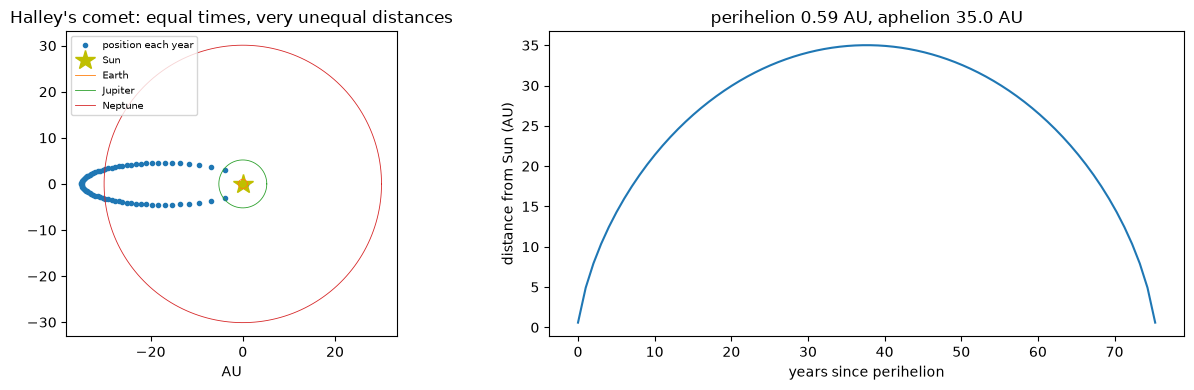

Fraction of its orbit Halley spends inside Jupiter's orbit: 5.3%


In [2]:
def solve_kepler(M, e, tol=1e-14, max_iter=50):
    """Solve M = E - e sin E for E by Newton-Raphson. Works on numpy arrays of M."""
    M = np.asarray(M, dtype=float)
    E = M + e*np.sin(M) if e < 0.8 else np.pi*np.ones_like(M)     # a good starting guess
    for _ in range(max_iter):
        dE = (E - e*np.sin(E) - M) / (1 - e*np.cos(E))
        E -= dE
        if np.max(np.abs(dE)) < tol:
            break
    return E

# Halley's comet: a = 17.8 AU, e = 0.967, T = 75.3 yr
a, e, T = 17.8, 0.967, 75.3
t = np.linspace(0, T, 76)                    # one point per year since perihelion
E = solve_kepler(2*np.pi*t/T, e)
x, y = a*(np.cos(E) - e), a*np.sqrt(1 - e**2)*np.sin(E)
r = np.hypot(x, y)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(x, y, 'o', ms=3, label='position each year')
ax1.plot(0, 0, 'y*', ms=15, label='Sun')
th = np.linspace(0, 2*np.pi, 200)
for R, name in [(1, 'Earth'), (5.2, 'Jupiter'), (30.1, 'Neptune')]:
    ax1.plot(R*np.cos(th), R*np.sin(th), lw=0.6, label=name)
ax1.set_aspect('equal'); ax1.set_xlabel('AU'); ax1.legend(fontsize=7, loc='upper left')
ax1.set_title("Halley's comet: equal times, very unequal distances")
ax2.plot(t, r); ax2.set_xlabel('years since perihelion'); ax2.set_ylabel('distance from Sun (AU)')
ax2.set_title(f'perihelion {r.min():.2f} AU, aphelion {r.max():.1f} AU')
plt.tight_layout(); plt.show()
print(f'Fraction of its orbit Halley spends inside Jupiter\'s orbit: {np.mean(r < 5.2):.1%}')

# A1.2 The structure of stars: the Lane-Emden equation <a class="anchor" id="lane-emden"></a>
A star is a ball of gas in **hydrostatic equilibrium**: pressure pushes out, gravity pulls in,

$$\frac{dP}{dr} = -\frac{G m(r)\rho}{r^2},\qquad \frac{dm}{dr} = 4\pi r^2\rho.$$

If the pressure depends only on density as a **polytrope**, $P = K\rho^{1+1/n}$, then writing $\rho = \rho_c\theta^n$ and $r = \alpha\xi$ (with a suitable length-scale $\alpha$) these combine into the dimensionless **Lane-Emden equation**:

$$\frac{1}{\xi^2}\frac{d}{d\xi}\left(\xi^2\frac{d\theta}{d\xi}\right) = -\theta^n, \qquad \theta(0)=1,\ \theta'(0)=0.$$

The surface of the star is the first zero $\xi_1$ of $\theta$. Only $n=0,1,5$ have analytic solutions; $n=1.5$ describes fully convective stars and white dwarfs, $n=3$ the Sun (roughly) and massive stars.

**Numerical issues:**
1. As a first-order system with $y=(\theta, \phi=\theta')$: $\theta'=\phi$, $\phi'=-\theta^n - \frac{2}{\xi}\phi$. The $2/\xi$ term is singular at $\xi=0$, so we start at small $\xi_0$ using the series solution $\theta\approx1-\xi^2/6 + n\xi^4/120$.
2. We need to stop exactly at $\theta=0$ - a job for an *event* in `solve_ivp` (which internally uses root finding!). Also, $\theta^n$ is undefined for $\theta<0$ with non-integer $n$, so we must stop there anyway.

 n    xi_1 (ours)   xi_1 (tables)   rho_c / <rho>
  0      2.44949       2.44949         1.00
  1      3.14159       3.14159         3.29
1.5      3.65375       3.65375         5.99
  3      6.89685       6.89685        54.18


  4     14.97155      14.97155       622.41


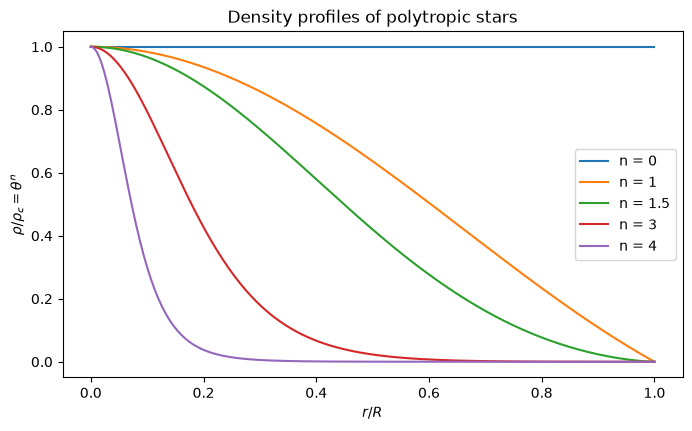

In [3]:
def lane_emden(n, xi_max=20):
    def rhs(xi, y):
        theta, phi = y
        return [phi, -np.sign(theta)*np.abs(theta)**n - 2*phi/xi]
    surface = lambda xi, y: y[0]
    surface.terminal, surface.direction = True, -1
    xi0 = 1e-6
    y0 = [1 - xi0**2/6 + n*xi0**4/120, -xi0/3 + n*xi0**3/30]
    return solve_ivp(rhs, (xi0, xi_max), y0, events=surface, rtol=1e-10, atol=1e-12, dense_output=True)

known = {0: np.sqrt(6), 1: np.pi, 1.5: 3.65375, 3: 6.89685, 4: 14.97155}
plt.figure(figsize=(8, 4.5))
print(' n    xi_1 (ours)   xi_1 (tables)   rho_c / <rho>')
for n in [0, 1, 1.5, 3, 4]:
    sol = lane_emden(n)
    xi1 = sol.t_events[0][0]
    dtheta1 = sol.y_events[0][0][1]
    central_concentration = -xi1/(3*dtheta1)        # rho_c/<rho> = -xi_1 / (3 theta'(xi_1))
    print(f'{n:>3}   {xi1:10.5f}    {known[n]:10.5f}     {central_concentration:8.2f}')
    xi = np.linspace(1e-6, xi1, 300)
    plt.plot(xi/xi1, np.clip(sol.sol(xi)[0], 0, None)**n, label=f'n = {n}')   # clip tiny negative round-off
plt.xlabel(r'$r/R$'); plt.ylabel(r'$\rho/\rho_c = \theta^n$'); plt.legend()
plt.title('Density profiles of polytropic stars'); plt.show()

Higher $n$ means a more centrally-concentrated star: the $n=3$ model has a central density 54 times the mean (the real Sun: about 100).

**Physics bonus: the mass-radius relation of white dwarfs.** For a polytrope one can show that, for a fixed constant $K$, $M \propto R^{(3-n)/(1-n)}$. For a non-relativistic degenerate electron gas $n=1.5$, so $R\propto M^{-1/3}$: *heavier white dwarfs are smaller!* When the electrons become relativistic, $n\to3$ and the mass becomes independent of the radius - this is the **Chandrasekhar limit**, $M_\text{Ch}\approx1.44M_\odot$, which can be calculated from $\xi_1$ and $\theta'(\xi_1)$ of the $n=3$ solution:

$$M_\text{Ch} = 4\pi\left(\frac{K}{\pi G}\right)^{3/2}\xi_1^2|\theta'(\xi_1)|, \qquad K = \frac{(3\pi^2)^{1/3}\hbar c}{4(\mu_e m_H)^{4/3}}.$$

In [4]:
G, hbar, c, mH, Msun = 6.674e-11, 1.0546e-34, 2.998e8, 1.6726e-27, 1.989e30
mu_e = 2.0                                     # helium / carbon / oxygen white dwarf
K = (3*np.pi**2)**(1/3)*hbar*c / (4*(mu_e*mH)**(4/3))
sol = lane_emden(3)
xi1, dtheta1 = sol.t_events[0][0], sol.y_events[0][0][1]
M_ch = 4*np.pi*(K/(np.pi*G))**1.5 * xi1**2*abs(dtheta1)
print(f'Chandrasekhar mass = {M_ch/Msun:.3f} solar masses')

Chandrasekhar mass = 1.435 solar masses


# A1.3 Where to park a space telescope: the Lagrange points <a class="anchor" id="lagrange"></a>
In the frame co-rotating with the Earth around the Sun, there are five points where gravity and centrifugal force balance - the **Lagrange points**. The James Webb Space Telescope sits near **L2**, about 1.5 million km beyond the Earth.

In units where the Sun-Earth distance is 1, $G(M_\odot+M_\oplus)=1$, with mass ratio $\mu = M_\oplus/(M_\odot+M_\oplus)$, the Sun at $x=-\mu$ and the Earth at $x=1-\mu$, the force along the line joining them is

$$F(x) = x - \frac{(1-\mu)(x+\mu)}{|x+\mu|^3} - \frac{\mu(x-1+\mu)}{|x-1+\mu|^3}.$$

The collinear points L1, L2, L3 are the three roots of $F(x)=0$. Each lies in a bracket between the singularities, perfect for `brentq`.

L1: 1,491,411 km from Earth
L2: 1,501,390 km from Earth
L3: 0.999998 AU from the Sun, on the far side
Hill-sphere estimate (mu/3)^(1/3) = 1,496,416 km


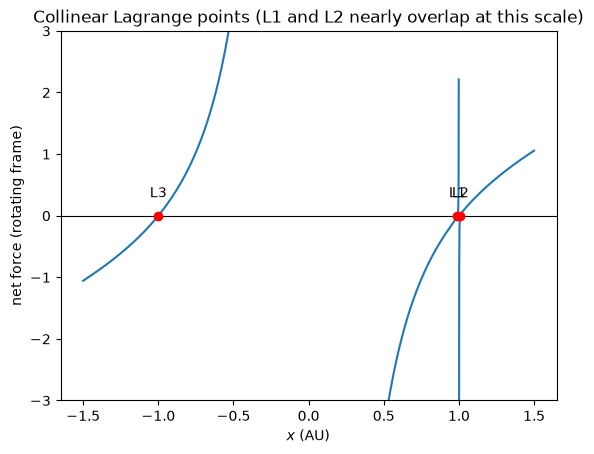

In [5]:
mu = 5.972e24/(1.989e30 + 5.972e24)
AU = 1.496e8                                          # km

def F(x):
    r1, r2 = x + mu, x - 1 + mu
    return x - (1 - mu)*r1/np.abs(r1)**3 - mu*r2/np.abs(r2)**3

eps = 1e-6
L1 = brentq(F, 1 - mu - 0.5, 1 - mu - eps)
L2 = brentq(F, 1 - mu + eps, 1 - mu + 0.5)
L3 = brentq(F, -1.5, -mu - eps)
for name, L in [('L1', L1), ('L2', L2)]:
    print(f'{name}: {abs(L - (1 - mu))*AU:,.0f} km from Earth')
print(f'L3: {abs(L3 + mu)*AU/AU:.6f} AU from the Sun, on the far side')
print(f'Hill-sphere estimate (mu/3)^(1/3) = {(mu/3)**(1/3)*AU:,.0f} km')

x = np.linspace(-1.5, 1.5, 3000)
Fx = F(x)
Fx[np.abs(Fx) > 5] = np.nan                           # don't draw lines across the singularities
plt.plot(x, Fx)
plt.axhline(0, color='k', lw=0.8); plt.ylim(-3, 3)
for L, name in [(L1, 'L1'), (L2, 'L2'), (L3, 'L3')]:
    plt.plot(L, 0, 'ro'); plt.annotate(name, (L, 0.3), ha='center')
plt.xlabel('$x$ (AU)'); plt.ylabel('net force (rotating frame)')
plt.title('Collinear Lagrange points (L1 and L2 nearly overlap at this scale)'); plt.show()

# A1.4 Gravitational N-body simulation <a class="anchor" id="nbody"></a>
The motion of $N$ bodies under mutual gravity,

$$\ddot{\mathbf r}_i = -\sum_{j\ne i}\frac{G m_j(\mathbf r_i - \mathbf r_j)}{\left(|\mathbf r_i - \mathbf r_j|^2 + \epsilon^2\right)^{3/2}},$$

has no general solution for $N\ge3$. Simulations of it have been used to understand everything from planetary stability to galaxy collisions and the cosmic web. (The small *softening length* $\epsilon$ prevents infinite forces in close encounters; we set it to 0 here.)

For long simulations we want an integrator that conserves energy well over many orbits: **velocity Verlet** (Chapter 5.6). We vectorise the force calculation with numpy *broadcasting*: `r[:, None, :] - r[None, :, :]` produces the full $N\times N$ array of separation vectors in one go.

**The figure-eight orbit.** In 1993 Cris Moore discovered numerically that three equal masses can chase each other around a figure-eight - a beautiful, *stable* periodic solution of the three-body problem (later proved to exist by Chenciner & Montgomery).

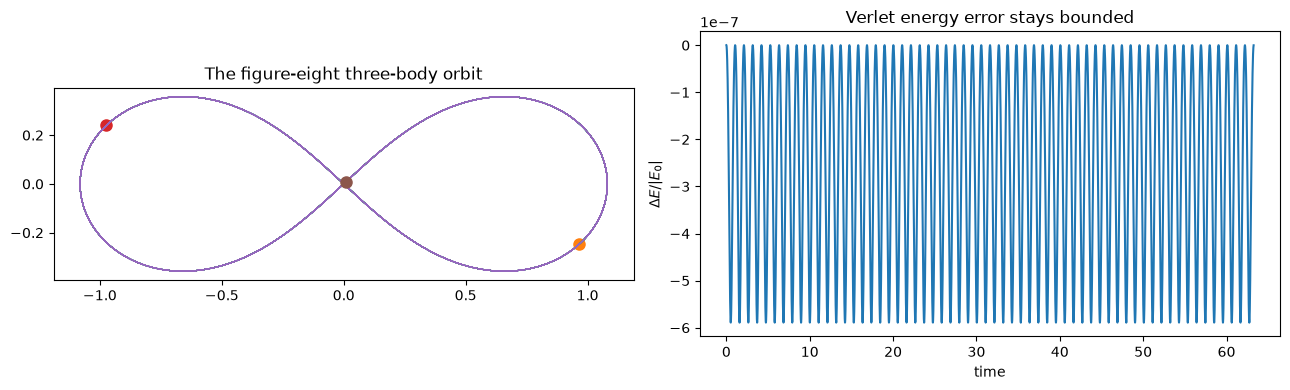

In [6]:
def accelerations(r, m, G=1.0, eps=0.0):
    d = r[None, :, :] - r[:, None, :]                  # d[i, j] = r_j - r_i
    dist3 = (np.sum(d**2, axis=-1) + eps**2)**1.5
    np.fill_diagonal(dist3, np.inf)                    # no self-force
    return G*np.sum(m[None, :, None]*d/dist3[:, :, None], axis=1)

def nbody_verlet(r0, v0, m, dt, n_steps, store_every=10):
    r, v = r0.copy(), v0.copy()
    a = accelerations(r, m)
    traj, energy = [], []
    for step in range(n_steps):
        v += 0.5*dt*a
        r += dt*v
        a = accelerations(r, m)
        v += 0.5*dt*a
        if step % store_every == 0:
            traj.append(r.copy())
            d = np.linalg.norm(r[:, None] - r[None, :], axis=-1)
            iu = np.triu_indices(len(m), 1)
            energy.append(0.5*np.sum(m*np.sum(v**2, axis=1)) - np.sum(m[iu[0]]*m[iu[1]]/d[iu]))
    return np.array(traj), np.array(energy)

# Initial conditions of the figure-eight (G = m = 1)
r0 = np.array([[0.97000436, -0.24308753], [-0.97000436, 0.24308753], [0.0, 0.0]])
v3 = np.array([-0.93240737, -0.86473146])
v0 = np.array([-v3/2, -v3/2, v3])
m = np.ones(3)
traj, energy = nbody_verlet(r0, v0, m, dt=1e-3, n_steps=63260)        # ~10 periods

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for i in range(3):
    ax1.plot(traj[:, i, 0], traj[:, i, 1], lw=0.8)
    ax1.plot(*traj[-1, i], 'o', ms=8)
ax1.set_aspect('equal'); ax1.set_title('The figure-eight three-body orbit')
ax2.plot(np.arange(len(energy))*10e-3, (energy - energy[0])/abs(energy[0]))
ax2.set_xlabel('time'); ax2.set_ylabel(r'$\Delta E/|E_0|$'); ax2.set_title('Verlet energy error stays bounded')
plt.tight_layout(); plt.show()

**Sun, Jupiter and the Trojan asteroids.** Jupiter's L4 and L5 points, $60^\circ$ ahead of and behind the planet, are *stable* (because the Sun/Jupiter mass ratio exceeds about 25). Thousands of "Trojan" asteroids are trapped there. Let's drop a few massless test particles near L4 and watch them librate on tadpole-shaped paths in the rotating frame. To exaggerate the effect (and keep the run short) we use a planet 10$\times$ heavier than Jupiter.

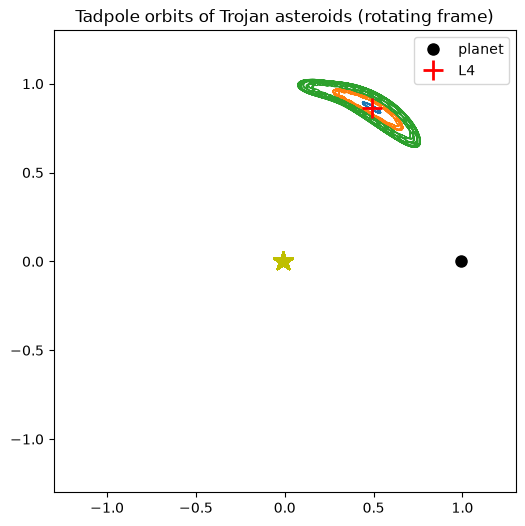

In [7]:
GM_sun, m_p = 1.0, 0.01                                   # units: a_planet = 1, G M_total = 1
m = np.array([1 - m_p, m_p, 0, 0, 0])
r0 = np.zeros((5, 2)); v0 = np.zeros((5, 2))
r0[0] = [-m_p, 0]; v0[0] = [0, -m_p]                       # Sun and planet on circular orbits
r0[1] = [1 - m_p, 0]; v0[1] = [0, 1 - m_p]                 # about the barycentre (angular speed 1)

# L4 makes an equilateral triangle with the Sun and planet
L4 = np.array([0.5 - m_p, np.sqrt(3)/2])
R_L4, phi_L4 = np.hypot(*L4), np.arctan2(L4[1], L4[0])
for k, dphi in zip(range(2, 5), [0.05, 0.2, 0.35]):       # displace each asteroid along the orbit
    phi = phi_L4 + dphi
    r0[k] = R_L4*np.array([np.cos(phi), np.sin(phi)])
    v0[k] = R_L4*np.array([-np.sin(phi), np.cos(phi)])    # co-rotating velocity
traj, _ = nbody_verlet(r0, v0, m, dt=2e-3, n_steps=300_000, store_every=50)

# transform to the frame rotating with the planet
ang = np.arctan2(traj[:, 1, 1], traj[:, 1, 0])
rot = np.stack([np.cos(-ang), -np.sin(-ang), np.sin(-ang), np.cos(-ang)], axis=-1).reshape(-1, 2, 2)
traj_rot = np.einsum('tij,tkj->tki', rot, traj)

plt.figure(figsize=(6, 6))
plt.plot(*traj_rot[:, 0].T, 'y*', ms=15)
plt.plot(*traj_rot[-1, 1], 'ko', ms=8, label='planet')
for k in range(2, 5):
    plt.plot(*traj_rot[:, k].T, lw=0.6)
plt.plot(*L4, 'r+', ms=15, mew=2, label='L4')
plt.gca().set_aspect('equal'); plt.legend(); plt.xlim(-1.3, 1.3); plt.ylim(-1.3, 1.3)
plt.title('Tadpole orbits of Trojan asteroids (rotating frame)'); plt.show()

The further an asteroid starts from L4, the bigger its tadpole - but it stays trapped. Try the exercise of giving one a small *radial* displacement or extra velocity instead: you'll find the trap is much less forgiving in that direction, and the asteroid can escape onto a chaotic orbit.

# A1.5 A galaxy's rotation curve and dark matter <a class="anchor" id="rotation"></a>
For stars in circular orbits in a galaxy, $v^2/r = GM(<r)/r^2$, so $v(r) = \sqrt{GM(<r)/r}$. If most of the mass were in the visible stars, $v$ should fall off like $r^{-1/2}$ (Keplerian) at large radius. Vera Rubin's measurements in the 1970s showed instead that rotation curves stay **flat** - the most direct evidence for dark matter.

Below we model a galaxy with a visible exponential disk (treated as spherical for simplicity) plus a dark-matter halo with an isothermal-like density $\rho_h(r)=\rho_0/(1+(r/r_c)^2)$, compute $M(<r)=\int_0^r 4\pi r'^2\rho\,dr'$ by **quadrature**, and **fit** the halo parameters to synthetic "observed" data.

rho0 = 10^(7.33 ± 0.14) Msun/kpc^3,  rc = 4.8 ± 1.0 kpc


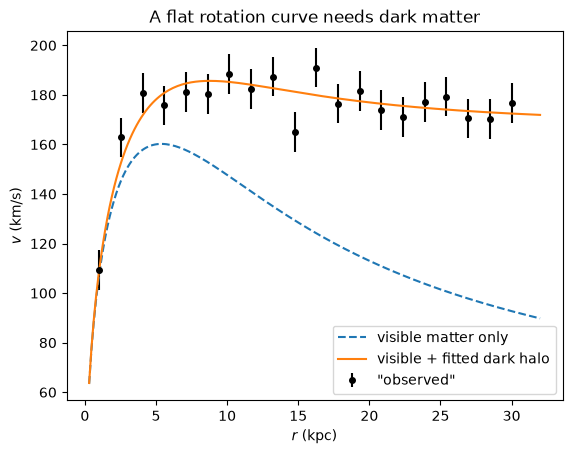

Dark matter fraction inside 30 kpc: 71%


In [8]:
G_kpc = 4.30091e-6                       # G in kpc (km/s)^2 / Msun
M_disk, R_d = 6e10, 3.0                  # visible mass (Msun) and scale length (kpc)

def M_visible(r):
    x = r/R_d
    return M_disk*(1 - (1 + x)*np.exp(-x))          # enclosed mass of an exponential profile

def M_halo(r, rho0, rc):
    integrand = lambda rp: 4*np.pi*rp**2*rho0/(1 + (rp/rc)**2)
    return np.array([quad(integrand, 0, ri)[0] for ri in np.atleast_1d(r)])

def v_circ(r, rho0, rc):
    return np.sqrt(G_kpc*(M_visible(r) + M_halo(r, rho0, rc))/r)

# Synthetic observations (truth: rho0 = 2e7 Msun/kpc^3, rc = 5 kpc)
rng = np.random.default_rng(11)
r_obs = np.linspace(1, 30, 20)
sig = 8.0*np.ones_like(r_obs)
v_obs = v_circ(r_obs, 2e7, 5.0) + rng.normal(0, sig)

popt, pcov = curve_fit(lambda r, lr, rc: v_circ(r, 10**lr, rc), r_obs, v_obs, p0=[7, 3], sigma=sig, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
print(f'rho0 = 10^({popt[0]:.2f} ± {perr[0]:.2f}) Msun/kpc^3,  rc = {popt[1]:.1f} ± {perr[1]:.1f} kpc')

r = np.linspace(0.3, 32, 200)
plt.errorbar(r_obs, v_obs, sig, fmt='ko', ms=4, label='"observed"')
plt.plot(r, np.sqrt(G_kpc*M_visible(r)/r), '--', label='visible matter only')
plt.plot(r, v_circ(r, 10**popt[0], popt[1]), label='visible + fitted dark halo')
plt.xlabel('$r$ (kpc)'); plt.ylabel('$v$ (km/s)'); plt.legend(); plt.title('A flat rotation curve needs dark matter')
plt.show()
M_tot = M_visible(30) + M_halo(30, 10**popt[0], popt[1])[0]
print(f'Dark matter fraction inside 30 kpc: {1 - M_visible(30)/M_tot:.0%}')

# Projects <a class="anchor" id="projects"></a>

1. **Hohmann transfer.** Use `solve_ivp` to send a spacecraft from Earth's orbit to Mars' orbit with a Hohmann transfer. Use the shooting method (Ch. 5.9) to find the launch $\Delta v$ that makes the spacecraft reach exactly 1.524 AU.
2. **Precession of Mercury.** Add the general-relativistic correction $\mathbf{a} = -\frac{GM}{r^3}\mathbf{r}\left(1 + \frac{3L^2}{c^2r^2}\right)$ to the Kepler problem (exaggerate the correction by a factor of $10^6$ so it's visible) and measure the precession of the perihelion per orbit. Scale back down and compare with the famous 43 arcseconds per century.
3. **Galaxy collision.** Model two "galaxies" as a heavy central mass surrounded by rings of massless test particles, and send them past each other. Can you make tidal tails like the Antennae galaxies? (Toomre & Toomre, 1972, did exactly this.)
4. **Isothermal sphere.** Solve the isothermal Lane-Emden equation $\frac{1}{\xi^2}\frac{d}{d\xi}\left(\xi^2\frac{d\psi}{d\xi}\right)=e^{-\psi}$ and show that at large $\xi$ the density falls as $\rho\propto r^{-2}$ - giving exactly the flat rotation curve of section A1.5.

In [9]:
# Start working here

In [10]:
print("Halley's comet is due back at perihelion in 2061. Set a reminder.")  # easter egg (deliberate)

Halley's comet is due back at perihelion in 2061. Set a reminder.
